# Mode-I crack: multiple source-position cold starts at one fixed b/a
No SVD, no least-squares correction. Kernel weights, source margins and KI are jointly trained with Adam/L-BFGS.
Four initial source boundaries; default b/a=2, h/a=6. Reference KI is used only for reporting error.
The reference is the finite-width Tada formula; a finite-height plate need not match it exactly.
Boundary residual is the square root of the weighted sum of boundary MSEs, excluding regularization.


In [11]:
# CUDA compatibility fix v3: ALL complex basis operations run on CPU.
# Only real-valued response matrices and coefficient training use the GPU.
# Revised KM-PIKFNN: exterior sources + Williams n=1,3,5 enrichment.
# Requires: numpy, scipy, torch, matplotlib. Reference K_I is evaluation only.
# No SVD initialization or coefficient correction; all runs are cold starts.

import math
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.linalg import lstsq as scipy_lstsq


import copy
import csv


In [12]:

# =========================
# 1) Configuration
# =========================

torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg = {
    # Geometry and loading
    "a": 1.0,
    "b": 2.0,
    "h": 6.0,
    "E": 1.0,
    "nu": 0.30,
    "sigma0": 1.0,
    "plane_strain": True,

    # Boundary collocation
    "n_top": 121,
    "n_side": 121,
    "n_crack": 100,
    "n_ligament": 100,
    "eps_crack": 1.0e-6,

    # Exterior point-force source points
    "n_src_side": 64,
    "src_margin_x_factor": 0.15,
    "src_margin_y_factor": 0.05,

    # Compatibility settings only: no tip clusters are generated
    "tip_cluster_count": 0,
    "tip_cluster_radii": [0.08, 0.16],
    "tip_cluster_angle_min_deg": 200.0,
    "tip_cluster_angle_max_deg": 340.0,

    # Optimization
    "adam_steps": 0,
    "adaptive_sources": True,
    "source_lr": 1.0e-3,
    "source_margin_x_bounds": [0.02, 0.60],
    "source_margin_y_bounds": [0.01, 0.30],
    "source_log_every": 50,

    "ls_warm_start": False,
    "svd_rcond": 1.0e-12,
    "higher_williams_orders": [1.5, 2.5],
    "adam_lr": 1.0e-3,
    "lbfgs_epochs": 300,
    "lbfgs_max_iter": 20,
    "lambda_reg": 1.0e-10,

    # Boundary weights
    "w_top": 2.5,
    "w_right": 1.5,
    "w_left": 2.0,
    "w_crack": 8.0,
    "w_ligament": 4.0,

    # Plotting
    "nx_plot": 141,
    "ny_plot": 141,
    "seed": 2026,
}

print("Version: ModeI_joint_cold_start_source_study")
print(f"CPU complex autograd; coefficient training device: {device}")
torch.manual_seed(cfg["seed"])
np.random.seed(cfg["seed"])

# Differentiable complex source geometry stays on CPU to avoid Windows NVRTC.
if cfg["adaptive_sources"]:
    device=torch.device("cpu")
    torch.set_num_threads(min(4,torch.get_num_threads()))
print(f"Adaptive source training: {cfg['adaptive_sources']}; device={device}")

# One fixed geometry; each run starts with ZERO kernel/enrichment/KI coefficients.
cfg["source_initial_values"]=[(0.05,0.02),(0.15,0.05),(0.30,0.10),(0.50,0.20)]
cfg["output_dir"]="mode_i_cold_start_source_study"


Version: ModeI_joint_cold_start_source_study
CPU complex autograd; coefficient training device: cuda
Adaptive source training: True; device=cpu


In [13]:

# =========================
# 2) Material constants
# =========================

E = cfg["E"]
nu = cfg["nu"]
mu = E / (2.0 * (1.0 + nu))

if cfg["plane_strain"]:
    lam = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
    kappa = 3.0 - 4.0 * nu
else:
    lam = E * nu / (1.0 - nu * nu)
    kappa = (3.0 - nu) / (1.0 + nu)

a = cfg["a"]
b = cfg["b"]
h = cfg["h"]
sigma0 = cfg["sigma0"]


def reference_ki_tada(a_value: float = a, b_value: float = b, sigma: float = sigma0) -> float:
    """Reference SIF used by the benchmark paper."""
    width_factor = 1.0 - 0.025 * (a_value / b_value) ** 2 + 0.06 * (a_value / b_value) ** 4
    finite_width = math.sqrt(1.0 / math.cos(math.pi * a_value / (2.0 * b_value)))
    return sigma * math.sqrt(math.pi * a_value) * width_factor * finite_width


KI_REF = reference_ki_tada()


In [14]:

# =========================
# 3) Geometry and source points
# =========================

def linspace_col(x0: float, x1: float, n: int) -> torch.Tensor:
    return torch.linspace(x0, x1, n, device=device).reshape(-1, 1)


def generate_boundary_points() -> dict[str, torch.Tensor]:
    eps = cfg["eps_crack"]

    x_top = linspace_col(0.0, b, cfg["n_top"])
    top = torch.cat([x_top, torch.full_like(x_top, h)], dim=1)

    y_right = linspace_col(0.0, h, cfg["n_side"])
    right = torch.cat([torch.full_like(y_right, b), y_right], dim=1)

    y_left = linspace_col(0.0, h, cfg["n_side"])
    left = torch.cat([torch.zeros_like(y_left), y_left], dim=1)

    x_crack = linspace_col(0.02 * a, 0.98 * a, cfg["n_crack"])
    crack = torch.cat([x_crack, torch.full_like(x_crack, eps)], dim=1)

    x_ligament = linspace_col(1.02 * a, b, cfg["n_ligament"])
    ligament = torch.cat([x_ligament, torch.zeros_like(x_ligament)], dim=1)

    return {
        "top": top,
        "right": right,
        "left": left,
        "crack": crack,
        "ligament": ligament,
    }


def generate_source_points() -> torch.Tensor:
    mx = cfg["src_margin_x_factor"] * b
    my = cfg["src_margin_y_factor"] * h
    n = cfg["n_src_side"]

    xs = torch.linspace(-mx, b + mx, n, device=device)
    ys = torch.linspace(-my, h + my, n, device=device)

    src = []
    for x in xs:
        src.append(torch.stack([x, torch.tensor(-my, device=device)]))
        src.append(torch.stack([x, torch.tensor(h + my, device=device)]))
    for y in ys[1:-1]:
        src.append(torch.stack([torch.tensor(-mx, device=device), y]))
        src.append(torch.stack([torch.tensor(b + mx, device=device), y]))


    return torch.stack(src, dim=0)


bnd_pts = generate_boundary_points()
src_pts = generate_source_points()

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D


def _as_numpy_points(points):
    if hasattr(points, "detach"):
        points = points.detach().cpu().numpy()
    return np.asarray(points, dtype=float).reshape(-1, 2)


def plot_mode_i_center_crack_sources(
    cfg,
    bnd_pts,
    src_pts,
    save_name="mode_i_center_crack_source_distribution.png",
    dpi=600,
    figsize=(5.4, 6.0),
    crack_tip_size=180,       # 裂尖五角星面积
    legend_width_ratio=0.94,  # 图例占内部宽度的比例
    show=True,
):
    """全部显示实际源点和边界配点，不抽样、不重新排点。"""
    a, b, h = (float(cfg[k]) for k in ("a", "b", "h"))
    mx = float(cfg["src_margin_x_factor"]) * b
    my = float(cfg["src_margin_y_factor"]) * h

    if not (0 < a < b and h > 0 and mx > 0 and my > 0):
        raise ValueError("需要 0 < a < b、h > 0，且源点外偏移为正。")

    sources = _as_numpy_points(src_pts)
    boundary = {
        name: _as_numpy_points(points)
        for name, points in bnd_pts.items()
    }
    groups = [p for p in boundary.values() if len(p)]
    all_boundary = (
        np.vstack(groups) if groups else np.empty((0, 2))
    )

    n_source = len(sources)
    n_boundary = len(all_boundary)
    n_unique = len(np.unique(all_boundary, axis=0))

    # 与方板受压模板一致
    BLACK = "#252525"
    GRAY = "#8C8C8C"
    RED = "#BE4540"
    BLUE = "#326A93"

    style = {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 11,
        "pdf.fonttype": 42,
        "svg.fonttype": "none",
    }

    with plt.rc_context(style):
        fig, ax = plt.subplots(figsize=figsize, dpi=180)
        fig.subplots_adjust(
            left=0.06, right=0.94, bottom=0.045, top=0.975
        )
        ax.set_facecolor("white")

        # 人工源点边界
        ax.plot(
            [-mx, b + mx, b + mx, -mx, -mx],
            [-my, -my, h + my, h + my, -my],
            color=GRAY, lw=1.0, ls=(0, (5, 4)),
            zorder=1,
        )

        # 物理边界：底边由裂面和对称韧带分别绘制
        ax.plot(
            [0, 0, b, b], [0, h, h, 0],
            color=BLACK, lw=1.5, zorder=2,
        )
        ax.plot(
            [0, a], [0, 0],
            color=RED, lw=2.0,
            solid_capstyle="butt", zorder=3,
        )
        ax.plot(
            [a, b], [0, 0],
            color=BLACK, lw=1.25,
            ls=(0, (5, 4)), zorder=3,
        )

        # 保留当前压缩布局，为上下源点留边距，防止标记被裁剪
        xpad = 0.04 * (b + 2 * mx)
        ypad = 0.035 * (h + 2 * my)
        ax.set_xlim(-mx - xpad, b + mx + xpad)
        ax.set_ylim(-my - ypad, h + my + ypad)
        ax.set_aspect("auto")
        ax.set_axis_off()

        fig.canvas.draw()

        def marker_size(points, max_diameter, min_diameter):
            """按画面最近点距选择标记直径，单位为 pt。"""
            points = np.unique(points, axis=0)
            if len(points) < 2:
                return max_diameter ** 2

            pixel_points = ax.transData.transform(points)

            # 分块计算最近点距，避免生成过大的距离矩阵
            nearest = np.inf
            for start in range(0, len(points), 256):
                stop = min(start + 256, len(points))
                delta = (
                    pixel_points[start:stop, None, :]
                    - pixel_points[None, :, :]
                )
                distances = np.sum(delta ** 2, axis=2)
                distances[
                    np.arange(stop - start),
                    np.arange(start, stop),
                ] = np.inf
                nearest = min(nearest, float(distances.min()))

            spacing_pt = np.sqrt(nearest) * 72.0 / fig.dpi
            diameter = np.clip(
                0.72 * spacing_pt,
                min_diameter,
                max_diameter,
            )
            return float(diameter ** 2)

        # 全部实际点：不使用抽样或插值。
        # 各边独立调整点大小，避免密集边上的圆点连成粗线。
        for points in boundary.values():
            if not len(points):
                continue
            ax.scatter(
                points[:, 0], points[:, 1],
                s=marker_size(points, 3.6, 0.65),
                marker="o", color=BLUE,
                edgecolors="none", linewidths=0,
                zorder=4,
            )

        # 源点也按四边分别控制标记尺寸
        covered = np.zeros(n_source, dtype=bool)
        tolerance = 1e-7 * max(b, h)

        for dim, value in (
            (1, -my), (1, h + my),
            (0, -mx), (0, b + mx),
        ):
            mask = (
                np.isclose(
                    sources[:, dim], value,
                    rtol=1e-6, atol=tolerance,
                )
                & ~covered
            )
            covered |= mask
            points = sources[mask]
            if len(points):
                ax.scatter(
                    points[:, 0], points[:, 1],
                    s=marker_size(points, 4.2, 0.8),
                    marker="s", color=RED,
                    edgecolors="none", linewidths=0,
                    zorder=5,
                )

        # 保留不在矩形边界上的其他真实源点
        remaining = sources[~covered]
        if len(remaining):
            ax.scatter(
                remaining[:, 0], remaining[:, 1],
                s=marker_size(remaining, 4.2, 0.8),
                marker="s", color=RED,
                edgecolors="none", linewidths=0,
                zorder=5,
            )

        ax.scatter(
            [a], [0],
            s=crack_tip_size, marker="*",
            color=BLACK, edgecolors="white",
            linewidths=0.55, zorder=7,
        )

        handles = [
            Line2D(
                [], [], color=BLACK, lw=1.5,
                label="Physical boundary",
            ),
            Line2D(
                [], [], color=GRAY, lw=1.0,
                ls=(0, (5, 4)),
                label="Artificial source boundary",
            ),
            Line2D(
                [], [], color=RED,
                marker="s", ls="none", markersize=5,
                label=f"Outer sources ($N_s={n_source}$)",
            ),
            Line2D(
                [], [], color=BLUE,
                marker="o", ls="none", markersize=5,
                label=f"Boundary collocation points ($N_b={n_boundary}$)",
            ),
            Line2D(
                [], [], color=RED, lw=2.0,
                label="Crack face",
            ),
            Line2D(
                [], [], color=BLACK, lw=1.25,
                ls=(0, (5, 4)),
                label="Symmetry ligament",
            ),
            Line2D(
                [], [], color=BLACK,
                marker="*", ls="none", markersize=12,
                label="Crack tip",
            ),
        ]

        legend_options = dict(
            handles=handles,
            loc="center",
            bbox_to_anchor=(b / 2, h / 2),
            bbox_transform=ax.transData,
            frameon=False,
            handlelength=1.8,
            handletextpad=0.6,
            labelspacing=1.15,
            borderaxespad=0,
            borderpad=0,
        )

        # 在内部空白范围内尽量放大图例，避免越过物理边界
        transform = ax.transData.transform
        interior_width = abs(
            transform((b, 0))[0] - transform((0, 0))[0]
        )
        interior_height = abs(
            transform((0, h))[1] - transform((0, 0))[1]
        )

        font_size = 16.0
        legend = ax.legend(fontsize=font_size, **legend_options)

        for _ in range(4):
            fig.canvas.draw()
            box = legend.get_window_extent(
                fig.canvas.get_renderer()
            )
            factor = min(
                legend_width_ratio * interior_width / box.width,
                0.78 * interior_height / box.height,
            )
            if abs(factor - 1.0) < 0.01:
                break
            font_size *= factor
            legend.remove()
            legend = ax.legend(
                fontsize=font_size, **legend_options
            )

        print(f"实际源点数量：{n_source}，全部绘制。")
        print(f"边界配点条目总数：{n_boundary}，全部绘制。")
        print(f"边界配点去重后坐标数量：{n_unique}。")
        for name, points in boundary.items():
            print(f"  {name}: {len(points)}")

        if show:
            plt.show()

    return fig, ax




In [15]:

# =========================
# 4) K-M formulas
# =========================

def km_response(
    z: torch.Tensor,
    phi: torch.Tensor,
    dphi: torch.Tensor,
    ddphi: torch.Tensor,
    psi: torch.Tensor,
    dpsi: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Kolosov-Muskhelishvili displacement and stress formulas."""
    stress_sum = 4.0 * torch.real(dphi)
    stress_diff_complex = 2.0 * (torch.conj(z) * ddphi + dpsi)
    stress_diff = torch.real(stress_diff_complex)
    sigma_xy = 0.5 * torch.imag(stress_diff_complex)
    sigma_xx = 0.5 * (stress_sum - stress_diff)
    sigma_yy = 0.5 * (stress_sum + stress_diff)

    displacement_complex = (kappa * phi - z * torch.conj(dphi) - torch.conj(psi)) / (2.0 * mu)
    ux = torch.real(displacement_complex)
    uy = torch.imag(displacement_complex)
    return ux, uy, sigma_xx, sigma_yy, sigma_xy


In [16]:

# =========================
# 5) Complex-potential basis functions
# =========================

def polynomial_basis_response(
    x: torch.Tensor,
    y: torch.Tensor,
    which: str,
    degree: int,
    coeff: complex,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Low-order polynomial K-M potential terms."""
    z = torch.complex(x.reshape(-1), y.reshape(-1))
    c = torch.as_tensor(coeff, dtype=z.dtype, device=z.device)

    if degree == 0:
        p = torch.ones_like(z)
        dp = torch.zeros_like(z)
        ddp = torch.zeros_like(z)
    elif degree == 1:
        p = z
        dp = torch.ones_like(z)
        ddp = torch.zeros_like(z)
    elif degree == 2:
        p = z * z
        dp = 2.0 * z
        ddp = 2.0 * torch.ones_like(z)
    else:
        raise ValueError("Only degree 0, 1, 2 are used.")

    zero = torch.zeros_like(z)
    if which == "phi":
        return km_response(z, c * p, c * dp, c * ddp, zero, zero)
    if which == "psi":
        return km_response(z, zero, zero, zero, c * p, c * dp)
    raise ValueError(which)


def complex_log_without_nvrtc(q: torch.Tensor) -> torch.Tensor:
    """Principal complex log using real CUDA kernels: log|q| + i atan2."""
    real_part = torch.log(torch.hypot(q.real, q.imag))
    imag_part = torch.atan2(q.imag, q.real)
    return torch.complex(real_part, imag_part)


def complex_power_without_nvrtc(q: torch.Tensor, exponent: float) -> torch.Tensor:
    """Principal q**exponent using real CUDA kernels, same branch as torch pow."""
    radius = torch.hypot(q.real, q.imag)
    angle = torch.atan2(q.imag, q.real)
    amplitude = torch.pow(radius, float(exponent))
    phase = float(exponent) * angle
    return torch.complex(amplitude * torch.cos(phase), amplitude * torch.sin(phase))


def complex_point_force_potential_response(
    x: torch.Tensor,
    y: torch.Tensor,
    sx: torch.Tensor,
    sy: torch.Tensor,
    fx: float,
    fy: float,
    add_kelvin_constant: bool = True,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Point-force fundamental solution written as K-M complex potentials.

    Let P = Fx + i Fy, q = z - zeta.  In the K-M convention used here,

        Phi = - P / [2 pi (kappa + 1)] log(q)
        Psi = kappa * conj(P) / [2 pi (kappa + 1)] log(q)
              + P * conj(zeta) / [2 pi (kappa + 1)] / q

    This pair gives the same stress field as the Kelvin point-force solution.
    Its displacement differs from the usual Kelvin displacement by a constant
    rigid translation.  Setting add_kelvin_constant=True adds a harmless
    constant to Phi so that the displacement also matches the standard Kelvin
    normalization.  Stresses are unchanged by this constant.
    """
    z = torch.complex(x.reshape(-1), y.reshape(-1))
    zeta = torch.complex(sx.reshape(()), sy.reshape(()))
    p_force = torch.as_tensor(complex(fx, fy), dtype=z.dtype, device=z.device)
    q = z - zeta

    den = 2.0 * math.pi * (kappa + 1.0)
    logq = complex_log_without_nvrtc(q)

    phi = -p_force / den * logq
    dphi = -p_force / den / q
    ddphi = p_force / den / (q * q)

    psi = kappa * torch.conj(p_force) / den * logq + p_force * torch.conj(zeta) / den / q
    dpsi = kappa * torch.conj(p_force) / den / q - p_force * torch.conj(zeta) / den / (q * q)

    if add_kelvin_constant:
        # Adds a constant displacement P / [4 pi mu (kappa + 1)].
        # This only shifts displacement, not stress.
        phi = phi + p_force / (2.0 * math.pi * kappa * (kappa + 1.0))

    return km_response(z, phi, dphi, ddphi, psi, dpsi)


def mode_i_tip_response(
    x: torch.Tensor,
    y: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Unit-K_I Mode-I crack-tip asymptotic field at the right tip (a, 0).

    This is currently written in the standard real LEFM near-tip form.  It is
    equivalent to a crack-tip K-M square-root potential and is used as the
    enrichment column whose coefficient is K_I.
    """
    xl = x.reshape(-1) - a
    yl = y.reshape(-1)
    r = torch.sqrt(torch.clamp(xl * xl + yl * yl, min=1.0e-20))
    theta = torch.atan2(yl, xl)

    c2 = torch.cos(0.5 * theta)
    s2 = torch.sin(0.5 * theta)
    s32 = torch.sin(1.5 * theta)
    c32 = torch.cos(1.5 * theta)

    root = torch.sqrt(r / (2.0 * math.pi))
    inv_root = 1.0 / torch.sqrt(2.0 * math.pi * r)

    ux = root * c2 * (kappa - 1.0 + 2.0 * s2 * s2) / (2.0 * mu)
    uy = root * s2 * (kappa + 1.0 - 2.0 * c2 * c2) / (2.0 * mu)
    sigma_xx = inv_root * c2 * (1.0 - s2 * s32)
    sigma_yy = inv_root * c2 * (1.0 + s2 * s32)
    sigma_xy = inv_root * s2 * c2 * c32
    return ux, uy, sigma_xx, sigma_yy, sigma_xy



def mode_i_higher_response(x: torch.Tensor, y: torch.Tensor, p: float):
    """Odd-order Mode-I Williams field, p=n/2 for n=3,5,... .

    A single-valued branch is used in the upper quarter-domain. The global
    KM coordinate z requires the translation correction -a*phi'. These are
    homogeneous elasticity solutions, not windowed or truncated fields.
    """
    if p <= 0.5 or abs(p - (round(p - 0.5) + 0.5)) > 1e-12:
        raise ValueError("Use p=1.5, 2.5, 3.5, ...")
    z = torch.complex(x.reshape(-1), y.reshape(-1))
    w = z - a
    if torch.any(torch.abs(w) == 0):
        raise ValueError("Do not evaluate the basis exactly at the crack tip")
    C = h ** (0.5 - p)
    phi = C * complex_power_without_nvrtc(w, p)
    dphi = C * p * complex_power_without_nvrtc(w, p - 1.0)
    ddphi = C * p * (p - 1.0) * complex_power_without_nvrtc(w, p - 2.0)
    psi = (1.0 - p) * phi - a * dphi
    dpsi = (1.0 - p) * dphi - a * ddphi
    return km_response(z, phi, dphi, ddphi, psi, dpsi)


def build_basis_columns(points: torch.Tensor) -> dict[str, torch.Tensor]:
    """Build response matrices.  The last column is the unit-K_I enrichment."""
    # Complex operations (including negation/division) can invoke NVRTC on
    # this Windows CUDA installation. Build the fixed basis on CPU only;
    # its real response matrices are transferred to the training device.
    output_device = points.device
    cpu_points = points.detach().to(device="cpu", dtype=torch.float64)
    x = cpu_points[:, 0:1]
    y = cpu_points[:, 1:2]
    cols: dict[str, list[torch.Tensor]] = {"ux": [], "uy": [], "sxx": [], "syy": [], "sxy": []}

    def add_response(response):
        for name, value in zip(("ux", "uy", "sxx", "syy", "sxy"), response):
            cols[name].append(value.reshape(-1))

    # # K-M polynomial background terms.
    # for which in ("phi", "psi"):
    #     for degree in (0, 1, 2):
    #         add_response(polynomial_basis_response(x, y, which, degree, 1.0 + 0.0j))
    #         add_response(polynomial_basis_response(x, y, which, degree, 0.0 + 1.0j))

    # K-M point-force fundamental solutions.
    for source in src_pts.detach().cpu():
        sx, sy = source[0], source[1]
        add_response(complex_point_force_potential_response(x, y, sx, sy, 1.0, 0.0))
        add_response(complex_point_force_potential_response(x, y, sx, sy, 0.0, 1.0))

    # Higher-order Williams terms are fitted independently of K_I.
    for p in cfg["higher_williams_orders"]:
        add_response(mode_i_higher_response(x, y, p))

    # Keep the unit-K_I leading enrichment LAST.
    add_response(mode_i_tip_response(x, y))

    result = {name: torch.stack(values, dim=1) for name, values in cols.items()}
    if any(value.is_complex() for value in result.values()):
        raise RuntimeError("Training matrices must be real-valued")
    return {name: value.to(output_device) for name, value in result.items()}


In [17]:

# =========================
# 6) Assemble basis matrices and scaling
# =========================

basis = {name: build_basis_columns(points) for name, points in bnd_pts.items()}
n_unknowns = basis["top"]["ux"].shape[1]


BOUNDARY_BLOCKS = [
    ("top", "syy", sigma0, "w_top"), ("top", "sxy", 0.0, "w_top"),
    ("right", "sxx", 0.0, "w_right"), ("right", "sxy", 0.0, "w_right"),
    ("left", "ux", 0.0, "w_left"), ("left", "sxy", 0.0, "w_left"),
    ("crack", "syy", 0.0, "w_crack"), ("crack", "sxy", 0.0, "w_crack"),
    ("ligament", "uy", 0.0, "w_ligament"), ("ligament", "sxy", 0.0, "w_ligament"),
]


def compute_column_scale() -> torch.Tensor:
    # Exactly the same sqrt(weight / point_count) as the mean-square loss.
    blocks = [math.sqrt(cfg[w] / basis[g][q].shape[0]) * basis[g][q]
              for g, q, target, w in BOUNDARY_BLOCKS]
    scale = torch.linalg.norm(torch.cat(blocks), dim=0).detach()
    return torch.where(scale > 0.0, scale, torch.ones_like(scale))


col_scale = compute_column_scale()


In [18]:
# Adaptive source parameterization and vectorized KM point-force matrices.
def adaptive_source_coordinates(factors):
    mx,my=factors[0]*b,factors[1]*h
    t=torch.linspace(0.,1.,cfg["n_src_side"],device=factors.device)
    xs=-mx+(b+2*mx)*t; ys=-my+(h+2*my)*t
    horizontal=torch.stack((torch.stack((xs,-my.expand_as(xs)),1),
                            torch.stack((xs,(h+my).expand_as(xs)),1)),1).reshape(-1,2)
    vertical=torch.stack((torch.stack((-mx.expand_as(ys[1:-1]),ys[1:-1]),1),
                          torch.stack(((b+mx).expand_as(ys[1:-1]),ys[1:-1]),1)),1).reshape(-1,2)
    return torch.cat((horizontal,vertical),0)


def differentiable_force_columns(points,sources):
    z=torch.complex(points[:,0],points[:,1])[:,None]
    s=torch.complex(sources[:,0],sources[:,1])[None,:]
    q=z-s; den=2*math.pi*(kappa+1.)
    logq=complex_log_without_nvrtc(q)
    responses=[]
    for force in (1.+0j,1j):
        P=torch.tensor(force,dtype=torch.complex128,device=points.device)
        phi=-P/den*logq+P/(2*math.pi*kappa*(kappa+1))
        dphi=-P/(den*q); ddphi=P/(den*q*q)
        psi=kappa*torch.conj(P)/den*logq+P*torch.conj(s)/(den*q)
        dpsi=kappa*torch.conj(P)/(den*q)-P*torch.conj(s)/(den*q*q)
        responses.append(km_response(z,phi,dphi,ddphi,psi,dpsi))
    return {name:torch.stack((responses[0][j],responses[1][j]),2).reshape(len(points),-1)
            for j,name in enumerate(("ux","uy","sxx","syy","sxy"))}


class KMPikfnnCrackModel(torch.nn.Module):
    def __init__(self,n_terms,scale):
        super().__init__()
        self.theta=torch.nn.Parameter(torch.zeros(n_terms,1,device=device))
        self.register_buffer("col_scale",scale.reshape(-1,1).clone())
        self.adaptive=cfg.get("adaptive_sources",False)
        lo=torch.tensor([cfg["source_margin_x_bounds"][0],cfg["source_margin_y_bounds"][0]],device=device)
        hi=torch.tensor([cfg["source_margin_x_bounds"][1],cfg["source_margin_y_bounds"][1]],device=device)
        initial=torch.tensor([cfg["src_margin_x_factor"],cfg["src_margin_y_factor"]],device=device)
        if torch.any(initial<=lo) or torch.any(initial>=hi):
            raise ValueError("Initial margins must lie strictly inside their bounds")
        self.register_buffer("margin_lo",lo);self.register_buffer("margin_hi",hi)
        raw=torch.logit((initial-lo)/(hi-lo))
        self.source_raw=torch.nn.Parameter(raw,requires_grad=self.adaptive)
        self._groups=list(bnd_pts)
        self._lengths=[len(bnd_pts[g]) for g in self._groups]
        self.register_buffer("boundary_points",torch.cat([bnd_pts[g] for g in self._groups]))
        nforce=2*len(src_pts)
        for j,g in enumerate(self._groups):
            for name in ("ux","uy","sxx","syy","sxy"):
                self.register_buffer(f"fixed_{j}_{name}",basis[g][name][:,nforce:].detach().clone())
        self._basis=basis
        self.source_history=[]

    def source_factors(self):
        return self.margin_lo+(self.margin_hi-self.margin_lo)*torch.sigmoid(self.source_raw)

    def sources(self):
        return adaptive_source_coordinates(self.source_factors())

    def refresh_boundary_basis(self):
        if not self.adaptive:
            self._basis=basis;return
        force=differentiable_force_columns(self.boundary_points,self.sources())
        self._basis={g:{} for g in self._groups}
        for name,values in force.items():
            for j,(g,block) in enumerate(zip(self._groups,torch.split(values,self._lengths))):
                self._basis[g][name]=torch.cat((block,getattr(self,f"fixed_{j}_{name}")),1)

    def coeffs(self):return self.theta/self.col_scale
    def group_quantity(self,group,quantity):return self._basis[group][quantity]@self.coeffs()
    def regularization(self):return torch.mean(self.theta[:-1]**2)


model=KMPikfnnCrackModel(n_unknowns,col_scale).to(device)


def publish_adaptive_sources(net):
    global src_pts,basis
    if net.adaptive:
        with torch.no_grad():
            src_pts=net.sources().detach().clone()
            net.refresh_boundary_basis()
            basis={g:{q:v.detach().clone() for q,v in blocks.items()} for g,blocks in net._basis.items()}
            fx,fy=net.source_factors().tolist()
            cfg["src_margin_x_factor"]=fx;cfg["src_margin_y_factor"]=fy



In [19]:

# =========================
# 8) Boundary-condition loss
# =========================

def boundary_group_losses(net: KMPikfnnCrackModel) -> tuple[torch.Tensor, dict[str, float]]:
    net.refresh_boundary_basis()
    detail: dict[str, float] = {}

    # Top: remote tension.
    syy_top = net.group_quantity("top", "syy")
    sxy_top = net.group_quantity("top", "sxy")
    loss_top = torch.mean((syy_top - sigma0) ** 2) + torch.mean(sxy_top ** 2)
    detail["top"] = loss_top.detach().item()

    # Right edge: traction free.
    sxx_right = net.group_quantity("right", "sxx")
    sxy_right = net.group_quantity("right", "sxy")
    loss_right = torch.mean(sxx_right ** 2) + torch.mean(sxy_right ** 2)
    detail["right"] = loss_right.detach().item()

    # Left symmetry: u_x = 0, sigma_xy = 0.
    ux_left = net.group_quantity("left", "ux")
    sxy_left = net.group_quantity("left", "sxy")
    loss_left = torch.mean(ux_left ** 2) + torch.mean(sxy_left ** 2)
    detail["left"] = loss_left.detach().item()

    # Crack face: traction free.
    syy_crack = net.group_quantity("crack", "syy")
    sxy_crack = net.group_quantity("crack", "sxy")
    loss_crack = torch.mean(syy_crack ** 2) + torch.mean(sxy_crack ** 2)
    detail["crack"] = loss_crack.detach().item()

    # Ligament symmetry ahead of crack tip.
    uy_lig = net.group_quantity("ligament", "uy")
    sxy_lig = net.group_quantity("ligament", "sxy")
    loss_ligament = torch.mean(uy_lig ** 2) + torch.mean(sxy_lig ** 2)
    detail["ligament"] = loss_ligament.detach().item()

    loss_reg = cfg["lambda_reg"] * net.regularization()
    detail["reg"] = loss_reg.detach().item()

    total = (
        cfg["w_top"] * loss_top
        + cfg["w_right"] * loss_right
        + cfg["w_left"] * loss_left
        + cfg["w_crack"] * loss_crack
        + cfg["w_ligament"] * loss_ligament
        + loss_reg
    )
    detail["total"] = total.detach().item()
    return total, detail



Run 1: (0.05, 0.02) | b/a=2 | zero weights and KI; no SVD
initial     0 | ax=0.050000, ay=0.020000 | KI=0.00000000 | boundary=2.500e+00, residual=1.581e+00 | KI error=100.000%
L-BFGS     1 | ax=0.050434, ay=0.020036 | KI=0.10261689 | boundary=7.821e-02, residual=2.797e-01 | KI error=95.119%
L-BFGS    10 | ax=0.067096, ay=0.047112 | KI=2.14644740 | boundary=6.986e-05, residual=8.358e-03 | KI error=2.088%
L-BFGS    20 | ax=0.073981, ay=0.047172 | KI=2.14721727 | boundary=4.168e-05, residual=6.456e-03 | KI error=2.125%
L-BFGS    30 | ax=0.080186, ay=0.046676 | KI=2.14649612 | boundary=3.079e-05, residual=5.549e-03 | KI error=2.090%
L-BFGS    40 | ax=0.085498, ay=0.046721 | KI=2.14745339 | boundary=2.636e-05, residual=5.134e-03 | KI error=2.136%
L-BFGS    50 | ax=0.088625, ay=0.045939 | KI=2.14387853 | boundary=2.166e-05, residual=4.654e-03 | KI error=1.966%
L-BFGS    60 | ax=0.104200, ay=0.048358 | KI=2.14646253 | boundary=1.853e-05, residual=4.304e-03 | KI error=2.089%
L-BFGS    70 | ax

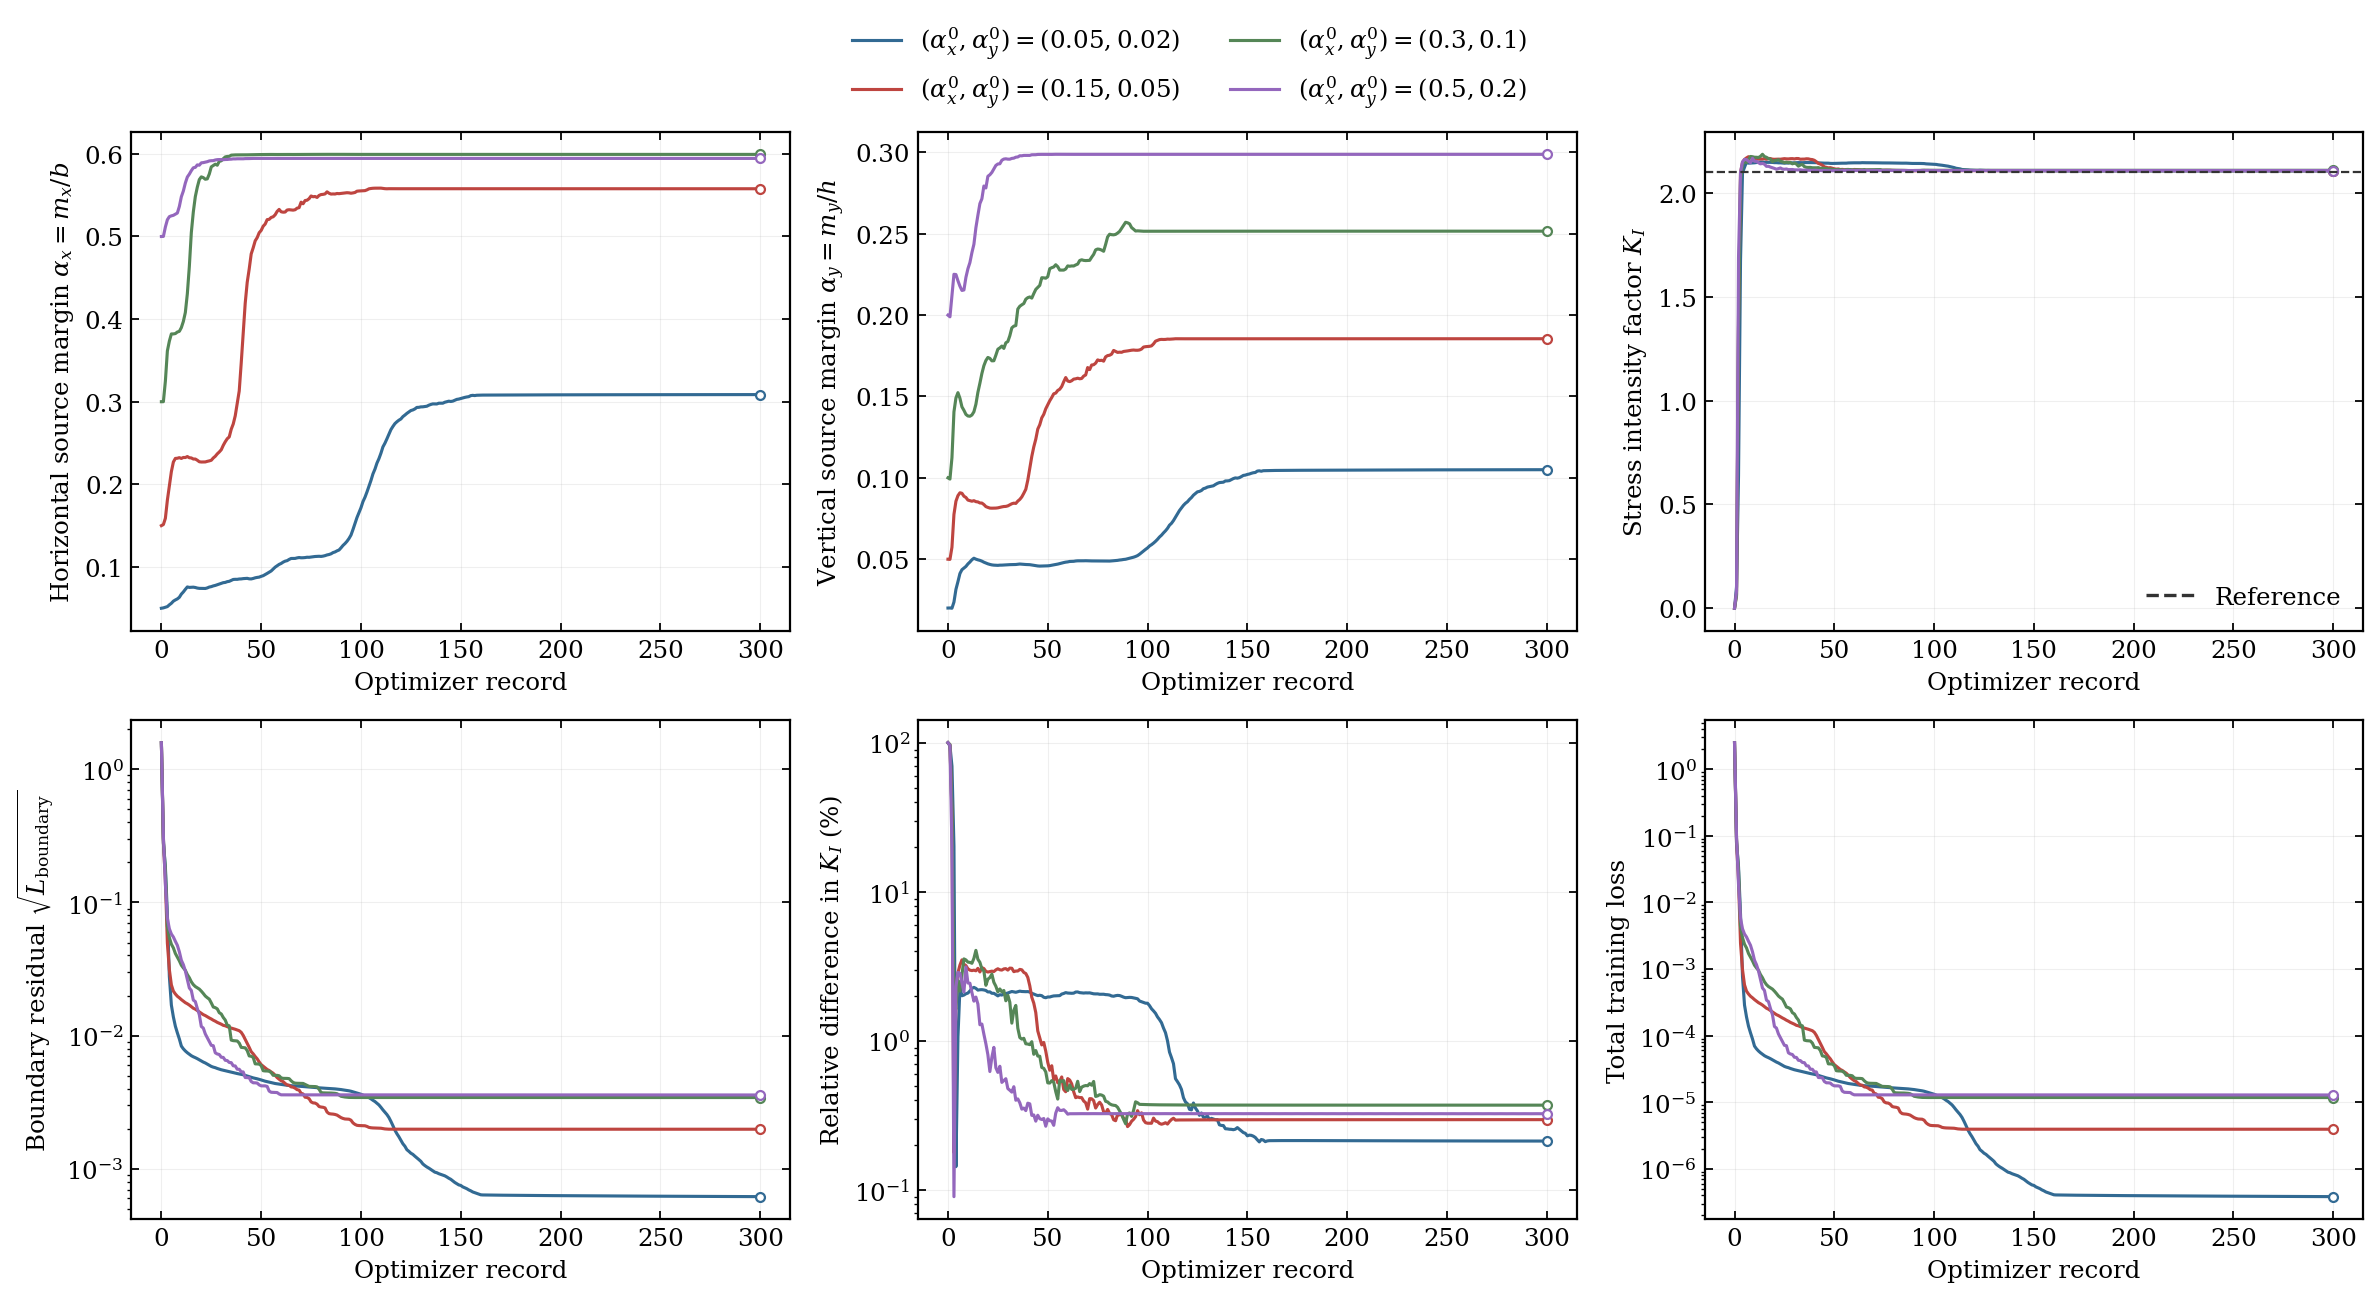

Dotted vertical line: Adam/L-BFGS transition; circles: adopted best states.
One record is one Adam step or one L-BFGS OUTER call, not one closure evaluation.


In [20]:
# Multiple cold starts at one fixed relative plate width.
# No SVD/least-squares solve is called anywhere in this notebook.
from pathlib import Path


def run_one_source_initialization(initial,index,base_cfg):
    global cfg,bnd_pts,src_pts,basis,n_unknowns,col_scale,model
    cfg=copy.deepcopy(base_cfg)
    cfg['src_margin_x_factor'],cfg['src_margin_y_factor']=map(float,initial)
    torch.manual_seed(cfg['seed']);np.random.seed(cfg['seed'])
    bnd_pts=generate_boundary_points();src_pts=generate_source_points()
    basis={g:build_basis_columns(pts) for g,pts in bnd_pts.items()}
    n_unknowns=basis['top']['ux'].shape[1];col_scale=compute_column_scale()
    model=KMPikfnnCrackModel(n_unknowns,col_scale).to(device)
    assert torch.count_nonzero(model.theta).item()==0
    ref=float(reference_ki_tada(a_value=a,b_value=b,sigma=sigma0))
    history=[];best_loss=float('inf');best_state=None;best_record=None
    t0=time.perf_counter()
    label=f'Run {index}: ({initial[0]:g}, {initial[1]:g})'
    print(f'\n{label} | b/a={b/a:g} | zero weights and KI; no SVD',flush=True)
    def record(stage,step,display=False):
        nonlocal best_loss,best_state,best_record
        with torch.no_grad():
            total,detail=boundary_group_losses(model)
            fx,fy=model.source_factors().tolist()
            ki=float(model.coeffs()[-1,0])
        # Weighted boundary loss excludes coefficient regularization.
        boundary=max(float(total)-detail['reg'],0.)
        row=dict(record=len(history),stage=stage,stage_step=step,
                 margin_x=fx,margin_y=fy,KI=ki,KI_reference=ref,
                 KI_relative_error=abs(ki-ref)/abs(ref),
                 weighted_boundary_loss=boundary,boundary_residual=np.sqrt(boundary),
                 total_loss=float(total),regularization=detail['reg'],
                 top_loss=detail['top'],right_loss=detail['right'],left_loss=detail['left'],
                 crack_loss=detail['crack'],ligament_loss=detail['ligament'])
        history.append(row)
        if row['total_loss']<best_loss:
            best_loss=row['total_loss'];best_state=copy.deepcopy(model.state_dict());best_record=row.copy()
        if display:
            print(f"{stage} {step:5d} | ax={fx:.6f}, ay={fy:.6f} | KI={ki:.8f} | "
                  f"boundary={boundary:.3e}, residual={np.sqrt(boundary):.3e} | "
                  f"KI error={row['KI_relative_error']:.3%}",flush=True)
    record('initial',0,True)
    optimizer=torch.optim.Adam([
        {'params':[model.theta],'lr':cfg['adam_lr']},
        {'params':[model.source_raw],'lr':cfg['source_lr']}])
    for epoch in range(1,cfg['adam_steps']+1):
        optimizer.zero_grad();total,_=boundary_group_losses(model)
        total.backward();optimizer.step()
        record('Adam',epoch,epoch==1 or epoch%cfg['source_log_every']==0 or epoch==cfg['adam_steps'])
    # Restore weights AND geometry together before the next stage.
    model.load_state_dict(best_state)
    optimizer=torch.optim.LBFGS([model.theta,model.source_raw],lr=1.,
        max_iter=cfg['lbfgs_max_iter'],max_eval=cfg['lbfgs_max_iter']+10,
        tolerance_grad=1e-12,tolerance_change=1e-14,history_size=100,line_search_fn='strong_wolfe')
    for epoch in range(1,cfg['lbfgs_epochs']+1):
        def closure():
            optimizer.zero_grad();total,_=boundary_group_losses(model)
            total.backward();return total
        optimizer.step(closure)
        record('L-BFGS',epoch,epoch==1 or epoch%10==0 or epoch==cfg['lbfgs_epochs'])
    model.load_state_dict(best_state)
    publish_adaptive_sources(model)
    folder=Path(base_cfg['output_dir']);folder.mkdir(parents=True,exist_ok=True)
    with (folder/f'run_{index}_history.csv').open('w',newline='',encoding='utf-8-sig') as f:
        writer=csv.DictWriter(f,fieldnames=list(history[0]));writer.writeheader();writer.writerows(history)
    np.savez(folder/f'run_{index}_best.npz',sources=src_pts.detach().cpu().numpy(),
             coefficients=model.coeffs().detach().cpu().numpy(),
             initial_factors=np.array(initial),final_factors=model.source_factors().detach().cpu().numpy(),
             KI_reference=ref,a=a,b=b,h=h,best_record=best_record['record'])
    summary=dict(run=index,initial_margin_x=initial[0],initial_margin_y=initial[1],
                 final_margin_x=best_record['margin_x'],final_margin_y=best_record['margin_y'],
                 KI=best_record['KI'],KI_reference=ref,
                 KI_relative_error=best_record['KI_relative_error'],
                 weighted_boundary_loss=best_record['weighted_boundary_loss'],
                 boundary_residual=best_record['boundary_residual'],total_loss=best_loss,
                 best_record=best_record['record'],best_stage=best_record['stage'],
                 elapsed_seconds=time.perf_counter()-t0)
    print(f"Best state: record={summary['best_record']}, ax={summary['final_margin_x']:.6f}, "
          f"ay={summary['final_margin_y']:.6f}, KI error={summary['KI_relative_error']:.3%}",flush=True)
    return dict(summary=summary,history=history,label=label)


def plot_source_initialization_study(results,base_cfg):
    colors=['#326A93','#BE4540','#558657','#9467BD','#D28C36','#4C9B9A']
    style={'font.family':'DejaVu Serif','mathtext.fontset':'dejavuserif','font.size':11,'axes.linewidth':1.}
    panels=[('margin_x',r'Horizontal source margin $\alpha_x=m_x/b$',False),
            ('margin_y',r'Vertical source margin $\alpha_y=m_y/h$',False),
            ('KI',r'Stress intensity factor $K_I$',False),
            ('boundary_residual',r'Boundary residual $\sqrt{L_{\mathrm{boundary}}}$',True),
            ('KI_relative_error',r'Relative difference in $K_I$ (%)',True),
            ('total_loss',r'Total training loss',True)]
    with plt.rc_context(style):
        fig,axes=plt.subplots(2,3,figsize=(15,8),dpi=160)
        for ax,(key,ylabel,logscale) in zip(axes.ravel(),panels):
            for j,result in enumerate(results):
                rows=result['history'];x=[r['record'] for r in rows]
                values=np.array([r[key] for r in rows])
                if key=='KI_relative_error':values*=100
                if logscale:values=np.maximum(values,1e-16)
                label=rf"$(\alpha_x^0,\alpha_y^0)=({result['summary']['initial_margin_x']:g},{result['summary']['initial_margin_y']:g})$"
                ax.plot(x,values,color=colors[j%len(colors)],lw=1.4,label=label)
                best=result['summary']['best_record']
                ax.plot(x[best],values[best],'o',color=colors[j%len(colors)],ms=4,mfc='white')
            if logscale:ax.set_yscale('log')
            if key=='KI':ax.axhline(results[0]['summary']['KI_reference'],color='#333333',ls='--',lw=1.,label='Reference')
            ax.set_xlabel('Optimizer record');ax.set_ylabel(ylabel)
            ax.tick_params(direction='in',top=True,right=True);ax.grid(alpha=.2,lw=.5)
        handles,labels=axes[0,0].get_legend_handles_labels()
        fig.legend(handles,labels,loc='upper center',ncol=2,frameon=False,bbox_to_anchor=(.5,1.02))
        axes[0,2].legend(handles=[plt.Line2D([],[],color='#333333',ls='--',label='Reference')],frameon=False)
        fig.tight_layout(rect=(0,0,1,.94))
        folder=Path(base_cfg['output_dir'])
        for ext in ('png','pdf'):fig.savefig(folder/f'cold_start_source_convergence.{ext}',dpi=400,bbox_inches='tight')
        plt.show();plt.close(fig)
    print('Dotted vertical line: Adam/L-BFGS transition; circles: adopted best states.')
    print('One record is one Adam step or one L-BFGS OUTER call, not one closure evaluation.')


def run_source_initialization_study():
    base=copy.deepcopy(cfg)
    results=[]
    for i,initial in enumerate(base['source_initial_values'],1):
        results.append(run_one_source_initialization(initial,i,base))
    folder=Path(base['output_dir'])
    with (folder/'initial_final_summary.csv').open('w',newline='',encoding='utf-8-sig') as f:
        writer=csv.DictWriter(f,fieldnames=list(results[0]['summary']))
        writer.writeheader();writer.writerows(r['summary'] for r in results)
    plot_source_initialization_study(results,base)
    return results


source_study_results=run_source_initialization_study()
